# Carbide Banana Detection
### Can a photo tell if a banana was ripened with calcium carbide?

Some sellers speed up ripening with **calcium carbide**. When it touches moisture it releases acetylene, which turns green bananas yellow in a day or two. It is banned for fruit ripening in India and Bangladesh because industrial grade carbide can carry traces of arsenic and phosphorus.

In this notebook I build a classic image processing pipeline (no deep learning) that takes a photo of bananas, cuts the bananas out, measures their color, spots and texture, and predicts **carbide** or **natural**.

**Data:** [Ripen Banana Dataset](https://data.mendeley.com/datasets/j9sp322drp) (Alam et al., 2025, CC BY 4.0). Sabri bananas from Bangladesh, shot on a white plate with an iPhone 11 every 2 hours.

**Result:** SVM on 13 hand made features, **90.9% test accuracy** and **88.7% 5 fold CV accuracy** on a balanced set of 656 photos.

### Contents
1. Setup
2. Data
3. Image acquisition
4. Representation (RGB vs HSV)
5. Enhancement
6. Restoration (noise test)
7. Segmentation
8. Counting bananas and spots
9. Feature extraction
10. Building the feature table
11. Classification
12. Evaluation
13. Conclusion

## 1. Setup

In [1]:
# import the libraries we need for this project
import os
import random
import time
import cv2                       # opencv for all the image processing
import numpy as np               # arrays and math
import pandas as pd              # tables
import matplotlib.pyplot as plt  # plots

# scikit learn is only used at the end for the classifier and the evaluation
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


In [2]:
# cleaned images made by prepare_data.py
DATA_FOLDER = os.path.join("data", "processed")

# plots used in the README
FIGURE_FOLDER = "images"
RESULTS_FOLDER = "results"
os.makedirs(FIGURE_FOLDER, exist_ok=True)
os.makedirs(RESULTS_FOLDER, exist_ok=True)

# fix the random seed so we get the same numbers every time we run the notebook
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# the two photos we use to show every step of the pipeline
CARBIDE_EXAMPLE = os.path.join(DATA_FOLDER, "carbide", "carbide_0115.jpg")
NATURAL_EXAMPLE = os.path.join(DATA_FOLDER, "natural", "natural_0968.jpg")

## 2. Data
Run `python prepare_data.py` once before this notebook. It reads the two zips from Mendeley and writes the cleaned images to `data/processed/`.

**Why not use all 7,814 images?** Most of them are augmented copies (rotated, flipped, zoomed or noisy) of only 1,404 real photos. If copies of the same photo land in both train and test, the model just recognizes the photo and the accuracy is inflated. So I kept one photo per scene:

1. Dropped rotated copies (they have black corners from the rotation).
2. Compared small grayscale thumbnails of every photo, including flipped and zoomed versions, and kept **one photo per group** of near matches.
3. Dropped zoomed in shots (bananas covering more than 38% of the frame), so both classes are shot from the same distance.
4. Resized from **3024 x 4032** to **756 x 1008** (one quarter per side, about 16x fewer pixels). Spots are still clearly visible.

Result: **328 carbide** photos (the paper reports 311 originals, so this lines up) and **1,034 natural** photos. `data/source_files.csv` maps every kept image back to its original file name.

In [3]:
# count how many images we have in each class
carbide_files = sorted(f for f in os.listdir(os.path.join(DATA_FOLDER, "carbide")) if f.endswith(".jpg"))
natural_files = sorted(f for f in os.listdir(os.path.join(DATA_FOLDER, "natural")) if f.endswith(".jpg"))

print("Carbide images:", len(carbide_files))
print("Natural images:", len(natural_files))

Carbide images: 328
Natural images: 1034


## 3. Image acquisition
* Camera: iPhone 11 (12 MP), daylight, plain white plate, 4 bananas per photo.
* Original resolution: 3024 x 4032 pixels. We work with 756 x 1008 pixels.
* OpenCV reads images as **BGR**, so we convert to **RGB** before showing them .

In [4]:
def load_image(filename):
    '''
    summary: read an image from the disk and convert it to RGB
    parameters: filename - path of the image
    return value: the image as an RGB array
    '''
    image = cv2.imread(filename)                     # opencv reads the image as BGR
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)   # convert to RGB for matplotlib
    return image


carbide_img = load_image(CARBIDE_EXAMPLE)
natural_img = load_image(NATURAL_EXAMPLE)

# image information
height, width, channels = carbide_img.shape
print("Height:", height)
print("Width:", width)
print("Channels:", channels)
print("Total pixels:", height * width)

# look at one pixel on the top banana
x, y = 400, 160
print("Pixel value at (x=400, y=160) as R, G, B:", carbide_img[y, x])

Height: 1008
Width: 756
Channels: 3
Total pixels: 762048
Pixel value at (x=400, y=160) as R, G, B: [127 124  31]


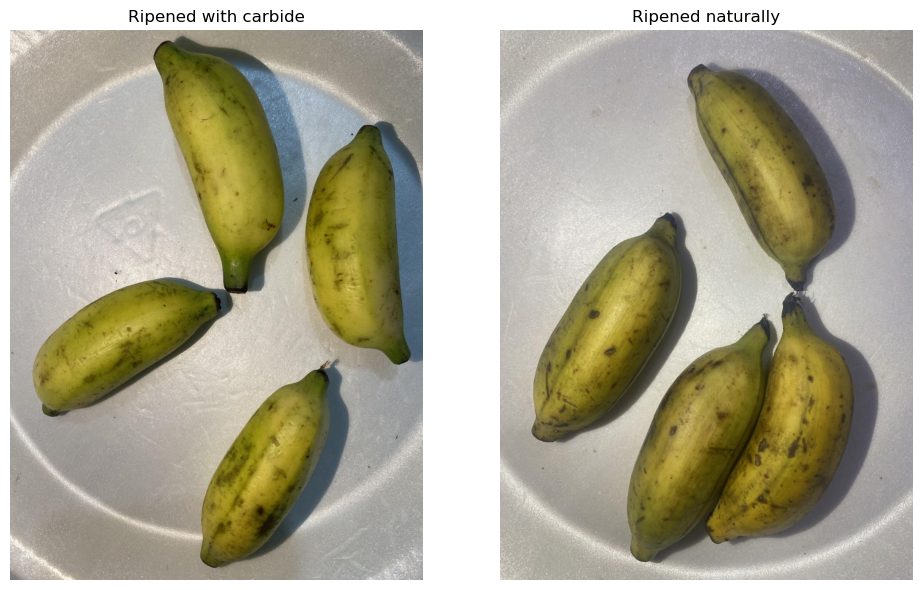

In [5]:
# show the two example photos side by side
fig, ax = plt.subplots(1, 2, figsize=(10, 6))
ax[0].imshow(carbide_img)
ax[0].set_title("Ripened with carbide")
ax[0].axis("off")
ax[1].imshow(natural_img)
ax[1].set_title("Ripened naturally")
ax[1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig01_examples.png"), dpi=150, bbox_inches="tight")
plt.show()

## 4. Representation (RGB vs HSV)
* A digital image is a grid of numbers. Each pixel has 3 values (Red, Green, Blue) from 0 to 255.
* RGB mixes color and brightness together, so shadows change all three values.
* **HSV** splits the pixel into **Hue** (which color), **Saturation** (how strong the color is) and **Value** (how bright).
* The banana has strong color and the white plate has almost no color, so the **Saturation** channel separates them very well.

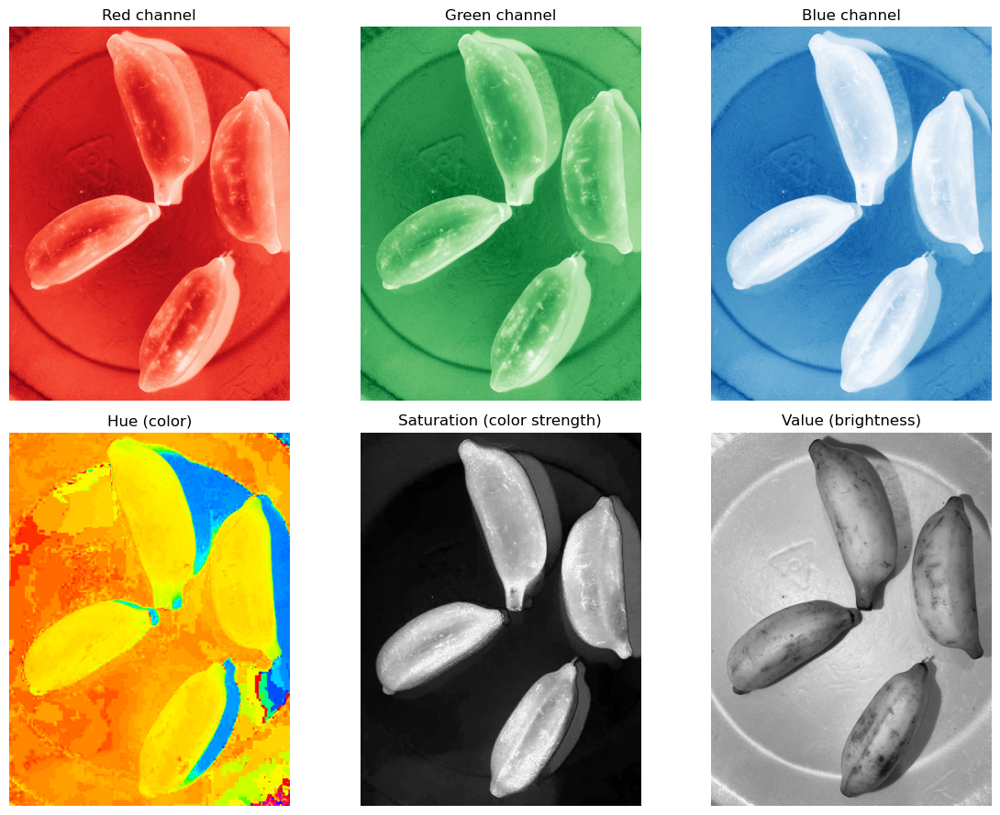

In [6]:
# split the RGB channels
red_channel = carbide_img[:, :, 0]
green_channel = carbide_img[:, :, 1]
blue_channel = carbide_img[:, :, 2]

# convert to HSV and split the channels
hsv = cv2.cvtColor(carbide_img, cv2.COLOR_RGB2HSV)
hue_channel = hsv[:, :, 0]         # opencv hue goes from 0 to 179
saturation_channel = hsv[:, :, 1]  # 0 = grey or white, 255 = very strong color
value_channel = hsv[:, :, 2]       # brightness

fig, ax = plt.subplots(2, 3, figsize=(12, 9))
ax[0, 0].imshow(red_channel, cmap="Reds")
ax[0, 0].set_title("Red channel")
ax[0, 1].imshow(green_channel, cmap="Greens")
ax[0, 1].set_title("Green channel")
ax[0, 2].imshow(blue_channel, cmap="Blues")
ax[0, 2].set_title("Blue channel")
ax[1, 0].imshow(hue_channel, cmap="hsv")
ax[1, 0].set_title("Hue (color)")
ax[1, 1].imshow(saturation_channel, cmap="gray")
ax[1, 1].set_title("Saturation (color strength)")
ax[1, 2].imshow(value_channel, cmap="gray")
ax[1, 2].set_title("Value (brightness)")
for a in ax.flat:
    a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig02_channels.png"), dpi=150, bbox_inches="tight")
plt.show()

## 5. Enhancement
We use two techniques:
* **Bilateral filter** removes noise but keeps the edges sharp (it only averages pixels that are close **and** have a similar color). I use d = 9, sigmaColor = 75, sigmaSpace = 75.
* **CLAHE** (Contrast Limited Adaptive Histogram Equalization) fixes uneven light and shadows. We apply it only to the **L (lightness)** channel of the LAB color space, so the banana colors do not change.

In [7]:
def enhance_image(image):
    '''
    summary: remove noise and improve the contrast of the image
    parameters: image - RGB image
    return value: enhanced RGB image
    '''
    # bilateral filter: 9x9 neighbourhood, 75 for color similarity, 75 for distance
    smooth = cv2.bilateralFilter(image, 9, 75, 75)

    # move to LAB so we can work on lightness only
    lab = cv2.cvtColor(smooth, cv2.COLOR_RGB2LAB)
    L, A, B = cv2.split(lab)

    # CLAHE works on small 8x8 tiles, clipLimit stops it from boosting noise too much
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    L = clahe.apply(L)

    # put the channels back together and return to RGB
    enhanced = cv2.cvtColor(cv2.merge([L, A, B]), cv2.COLOR_LAB2RGB)
    return enhanced


carbide_enh = enhance_image(carbide_img)
natural_enh = enhance_image(natural_img)

# measure the contrast (spread of the grey levels) before and after
gray_before = cv2.cvtColor(carbide_img, cv2.COLOR_RGB2GRAY)
gray_after = cv2.cvtColor(carbide_enh, cv2.COLOR_RGB2GRAY)
print("Contrast before (std of grey levels):", round(gray_before.std(), 1))
print("Contrast after  (std of grey levels):", round(gray_after.std(), 1))

Contrast before (std of grey levels): 42.7
Contrast after  (std of grey levels): 49.1


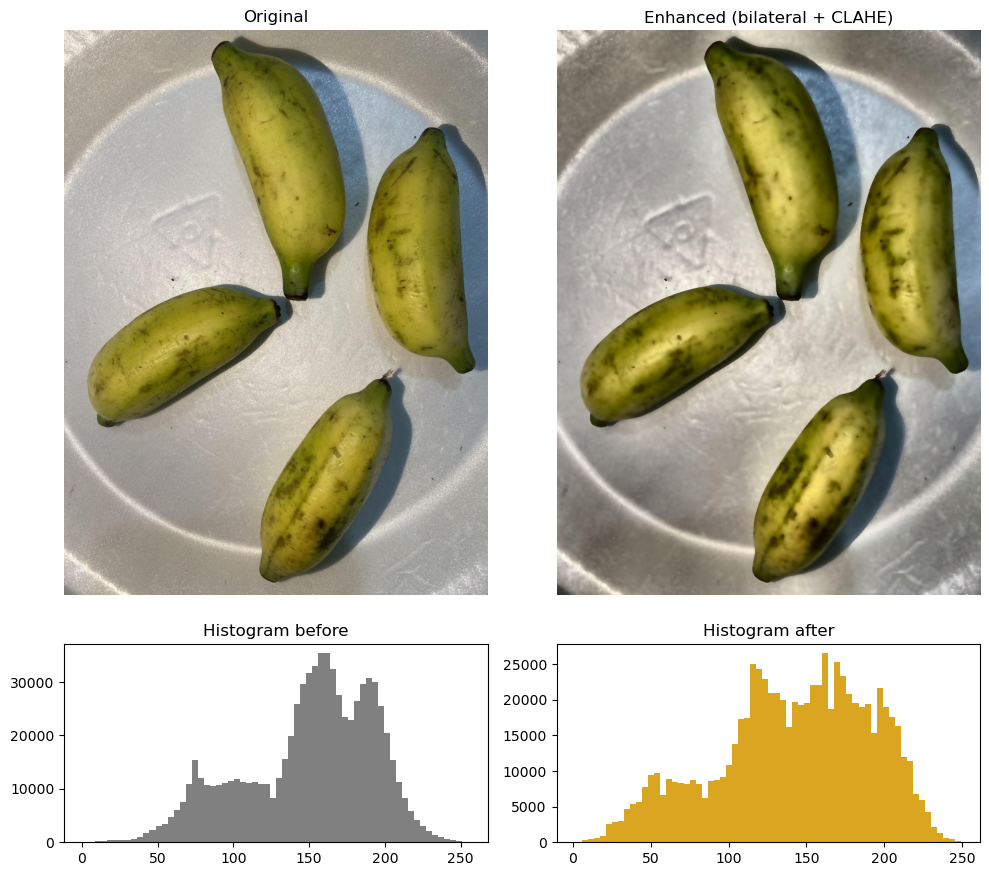

In [8]:
# compare before and after, with the grey level histograms
fig, ax = plt.subplots(2, 2, figsize=(10, 9), gridspec_kw={"height_ratios": [3, 1]})
ax[0, 0].imshow(carbide_img)
ax[0, 0].set_title("Original")
ax[0, 0].axis("off")
ax[0, 1].imshow(carbide_enh)
ax[0, 1].set_title("Enhanced (bilateral + CLAHE)")
ax[0, 1].axis("off")
ax[1, 0].hist(gray_before.ravel(), bins=64, color="grey")
ax[1, 0].set_title("Histogram before")
ax[1, 1].hist(gray_after.ravel(), bins=64, color="goldenrod")
ax[1, 1].set_title("Histogram after")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig03_enhancement.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Restoration (noise test)
* The dataset photos are clean, but a real inspector might take a photo in a dark market, which gives a **noisy** image.
* I add **Gaussian noise** to the photo and check if the enhancement step can clean it up.

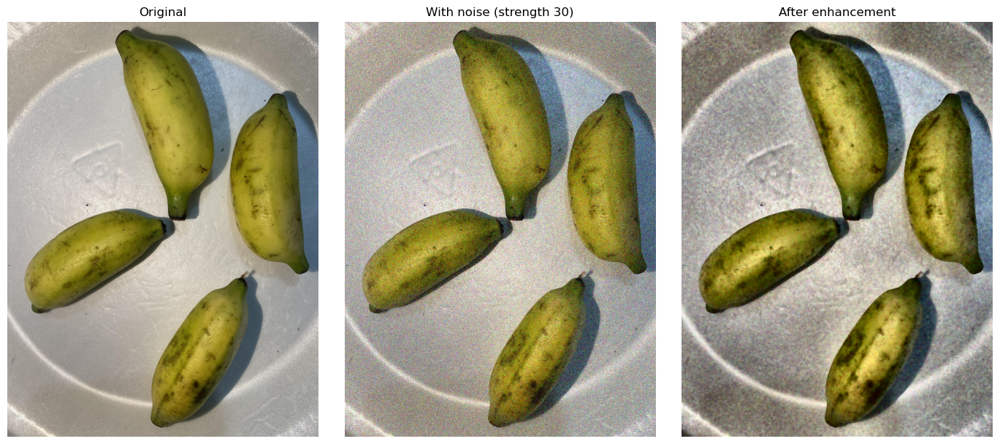

In [9]:
def add_noise(image, strength):
    '''
    summary: add random gaussian noise to an image
    parameters: image - RGB image, strength - standard deviation of the noise
    return value: noisy RGB image
    '''
    noise = np.random.normal(0, strength, image.shape)          # random numbers around 0
    noisy = np.clip(image + noise, 0, 255).astype(np.uint8)     # keep values between 0 and 255
    return noisy


noisy_img = add_noise(carbide_img, 30)
restored_img = enhance_image(noisy_img)

fig, ax = plt.subplots(1, 3, figsize=(14, 6))
ax[0].imshow(carbide_img)
ax[0].set_title("Original")
ax[1].imshow(noisy_img)
ax[1].set_title("With noise (strength 30)")
ax[2].imshow(restored_img)
ax[2].set_title("After enhancement")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig04_restoration.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Segmentation
* We take the **Saturation** channel and use **Otsu's method** to pick the threshold. Otsu looks at the histogram and finds the value that best splits it into two groups (banana and plate), so we do not have to guess a number.
* **Opening** (erode then dilate) removes small white dots. **Closing** (dilate then erode) fills small holes inside the bananas.
* Finally we keep only regions bigger than 1% of the image, so tiny leftovers are removed.

Otsu threshold picked for the saturation channel: 115.0
Percent of the image that is banana: 27.9 %


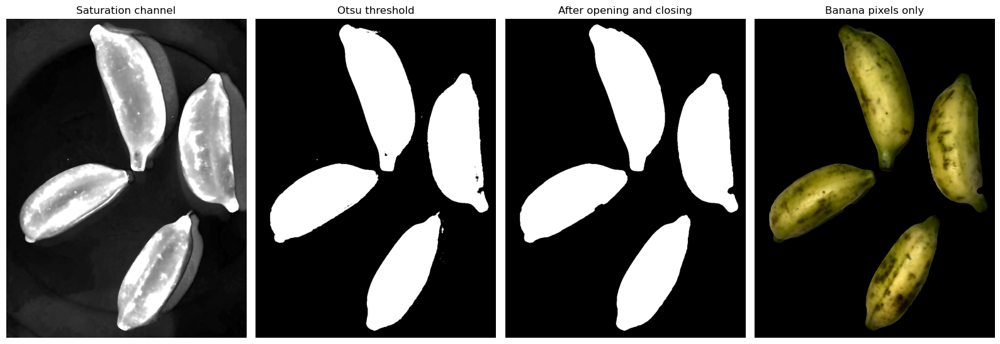

In [10]:
def segment_banana(image):
    '''
    summary: make a black and white mask where white = banana
    parameters: image - enhanced RGB image
    return value: clean mask, raw otsu mask, otsu threshold value
    '''
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    saturation = hsv[:, :, 1]

    # otsu finds the best threshold by itself
    otsu_value, raw_mask = cv2.threshold(saturation, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # morphology to clean the mask
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, kernel, iterations=2)   # remove small dots
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=3)      # fill small holes

    # keep only the big regions (bigger than 1% of the image)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    big = [c for c in contours if cv2.contourArea(c) > 0.01 * mask.size]
    clean_mask = np.zeros_like(mask)
    cv2.drawContours(clean_mask, big, -1, 255, thickness=-1)

    return clean_mask, raw_mask, otsu_value


carbide_mask, carbide_raw_mask, otsu_value = segment_banana(carbide_enh)
print("Otsu threshold picked for the saturation channel:", otsu_value)
print("Percent of the image that is banana:", round(100 * (carbide_mask > 0).mean(), 1), "%")

# keep only the banana pixels to show the result
banana_only = carbide_enh.copy()
banana_only[carbide_mask == 0] = 0

fig, ax = plt.subplots(1, 4, figsize=(16, 6))
ax[0].imshow(cv2.cvtColor(carbide_enh, cv2.COLOR_RGB2HSV)[:, :, 1], cmap="gray")
ax[0].set_title("Saturation channel")
ax[1].imshow(carbide_raw_mask, cmap="gray")
ax[1].set_title("Otsu threshold")
ax[2].imshow(carbide_mask, cmap="gray")
ax[2].set_title("After opening and closing")
ax[3].imshow(banana_only)
ax[3].set_title("Banana pixels only")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig05_segmentation.png"), dpi=150, bbox_inches="tight")
plt.show()

## 8. Counting bananas and spots
* **Bananas:** each white region in the mask is counted. Bananas that touch each other join into one region, so this number can be lower than 4.
* **Brown spots:** we use the **black hat** operation. It finds small dark marks on a brighter surface, which is exactly what a brown spot is.
* We only keep spots inside the banana (we shrink the mask a little so the dark banana edges are not counted) and ignore anything smaller than 8 pixels.

Carbide | banana regions: 4 | brown spots: 81
Natural | banana regions: 3 | brown spots: 86


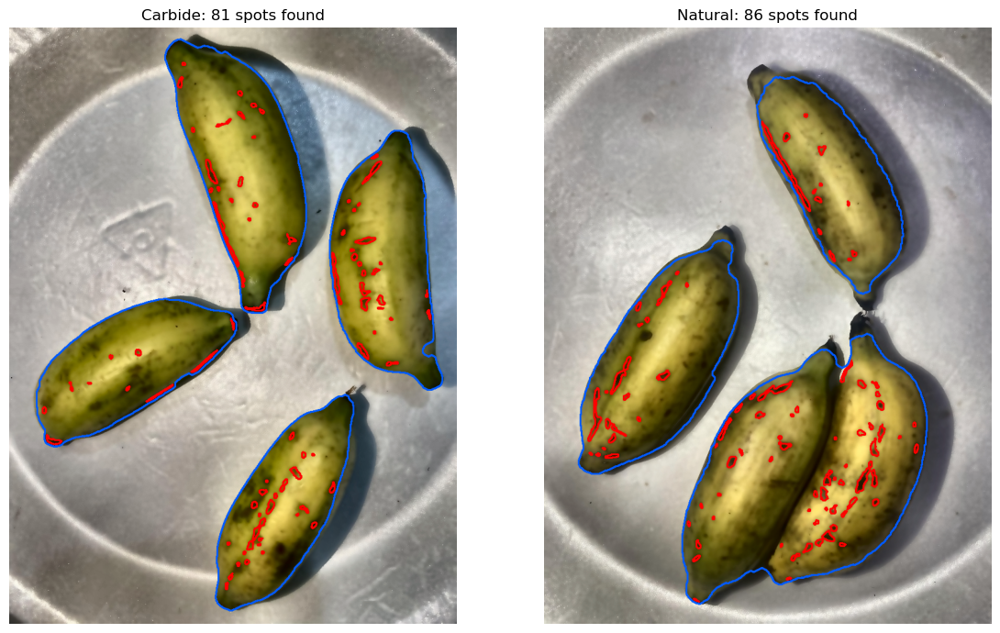

In [11]:
def count_spots(image, mask):
    '''
    summary: find the small dark brown spots on the banana skin
    parameters: image - enhanced RGB image, mask - banana mask
    return value: list of spot contours, the inner banana mask
    '''
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # black hat = closing minus the image, it makes small dark spots bright
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, spot_mask = cv2.threshold(blackhat, 25, 255, cv2.THRESH_BINARY)

    # shrink the banana mask a little so we do not count the dark edges
    inner = cv2.erode(mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    spot_mask = cv2.bitwise_and(spot_mask, inner)

    # every separate dark blob is one spot, ignore the very tiny ones
    contours, _ = cv2.findContours(spot_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    spots = [c for c in contours if cv2.contourArea(c) >= 8]
    return spots, inner


def count_bananas(mask):
    '''
    summary: count the separate banana regions in the mask
    '''
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return len(contours)


natural_mask, _, _ = segment_banana(natural_enh)

fig, ax = plt.subplots(1, 2, figsize=(12, 7))
for i, (name, enh, mask) in enumerate([("Carbide", carbide_enh, carbide_mask), ("Natural", natural_enh, natural_mask)]):
    spots, _ = count_spots(enh, mask)
    drawing = enh.copy()
    # draw every spot in red and the banana outline in blue
    cv2.drawContours(drawing, spots, -1, (255, 0, 0), 2)
    outline, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(drawing, outline, -1, (0, 90, 255), 2)
    print(name, "| banana regions:", count_bananas(mask), "| brown spots:", len(spots))
    ax[i].imshow(drawing)
    ax[i].set_title(f"{name}: {len(spots)} spots found")
    ax[i].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig06_spots.png"), dpi=150, bbox_inches="tight")
plt.show()

## 9. Feature extraction
Instead of giving the computer 760,000 pixels, we describe each photo with **13 numbers** measured on the banana pixels only (the plate is ignored):

| Feature | What it means |
|---|---|
| hue_mean | average color of the banana |
| hue_std | how even the color is (low = very even) |
| sat_mean, sat_std | how strong the color is, and how much it changes |
| bright_mean, bright_std | how bright the banana is, and how much it changes |
| yellow_ratio | share of banana pixels that are yellow |
| green_ratio | share of banana pixels that are green |
| lab_a_mean | green to red balance (LAB color space) |
| lab_b_mean | blue to yellow balance, used as a "yellowness" score |
| spot_count | number of brown spots |
| spot_area | share of the banana covered by spots |
| edge_density | texture, how many edges Canny finds on the skin |

In [12]:
def extract_features(filename):
    '''
    summary: run the full pipeline on one photo and return the 13 features
    parameters: filename - path of the image
    return value: dictionary with the features
    '''
    image = load_image(filename)          # step 1 acquisition
    enhanced = enhance_image(image)       # step 3 enhancement
    mask, _, _ = segment_banana(enhanced) # step 5 segmentation
    spots, inner = count_spots(enhanced, mask)  # step 6 counting

    # color values of the banana pixels only
    hsv = cv2.cvtColor(enhanced, cv2.COLOR_RGB2HSV)[mask > 0].astype(float)
    lab = cv2.cvtColor(enhanced, cv2.COLOR_RGB2LAB)[mask > 0].astype(float)
    hue, sat, bright = hsv[:, 0], hsv[:, 1], hsv[:, 2]

    # texture: edges found by canny inside the banana
    edges = cv2.Canny(cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY), 50, 150)
    inner_area = max(int((inner > 0).sum()), 1)

    return {
        "hue_mean": hue.mean(),
        "hue_std": hue.std(),
        "sat_mean": sat.mean(),
        "sat_std": sat.std(),
        "bright_mean": bright.mean(),
        "bright_std": bright.std(),
        "yellow_ratio": ((hue >= 18) & (hue < 30)).mean(),   # yellow hue range in opencv
        "green_ratio": ((hue >= 30) & (hue < 90)).mean(),    # green hue range in opencv
        "lab_a_mean": lab[:, 1].mean(),
        "lab_b_mean": lab[:, 2].mean(),
        "spot_count": len(spots),
        "spot_area": sum(cv2.contourArea(s) for s in spots) / inner_area,
        "edge_density": (edges[inner > 0] > 0).mean(),
    }


# feature vectors of the two example photos
example_features = pd.DataFrame([extract_features(CARBIDE_EXAMPLE), extract_features(NATURAL_EXAMPLE)],
                                index=["carbide example", "natural example"])
example_features.round(3).T

,carbide example,natural example
hue_mean,27.610,24.866
hue_std,2.670,2.081
sat_mean,203.528,173.132
sat_std,41.100,43.193
bright_mean,119.147,118.719
bright_std,52.919,58.027
yellow_ratio,0.829,0.979
green_ratio,0.168,0.017
lab_a_mean,121.524,125.254
lab_b_mean,170.269,163.061


## 10. Building the feature table
* We have 328 carbide photos and 1,034 natural photos. If we used all of them, a model that always says "natural" would already get 76% accuracy, which means nothing.
* So we use a **balanced set**: all 328 carbide photos and 328 natural photos picked at random. Now guessing gives only 50%.

In [13]:
# pick the same number of natural photos as carbide photos
natural_sample = random.sample(natural_files, len(carbide_files))

paths = [os.path.join(DATA_FOLDER, "carbide", f) for f in carbide_files] + \
        [os.path.join(DATA_FOLDER, "natural", f) for f in natural_sample]
labels = ["carbide"] * len(carbide_files) + ["natural"] * len(natural_sample)

# run the pipeline on every photo
start = time.time()
rows = []
for i, p in enumerate(paths):
    rows.append(extract_features(p))
    if (i + 1) % 100 == 0:
        print("processed", i + 1, "of", len(paths))

data = pd.DataFrame(rows)
data["label"] = labels
data["path"] = paths
print("Done in", round(time.time() - start, 1), "seconds")
print("Table size:", data.shape)

processed 100 of 656


processed 200 of 656


processed 300 of 656


processed 400 of 656


processed 500 of 656


processed 600 of 656


Done in 17.7 seconds
Table size: (656, 15)


In [14]:
# average of each feature for the two classes
data.groupby("label").mean(numeric_only=True).round(3).T

label,carbide,natural
hue_mean,31.017,31.493
hue_std,3.925,4.070
sat_mean,187.770,178.932
sat_std,47.666,47.700
bright_mean,111.492,106.344
bright_std,51.258,48.320
yellow_ratio,0.360,0.280
green_ratio,0.633,0.706
lab_a_mean,118.132,117.670
lab_b_mean,164.888,162.313


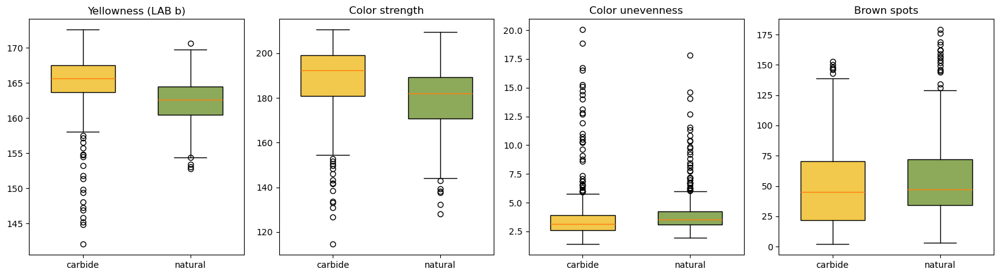

In [15]:
# box plots of four features that look different between the classes
show = [("lab_b_mean", "Yellowness (LAB b)"), ("sat_mean", "Color strength"),
        ("hue_std", "Color unevenness"), ("spot_count", "Brown spots")]

fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
for a, (col, title) in zip(ax, show):
    box = a.boxplot([data[data.label == "carbide"][col], data[data.label == "natural"][col]],
                    patch_artist=True, widths=0.6)
    box["boxes"][0].set_facecolor("#F2C94C")
    box["boxes"][1].set_facecolor("#8DAA5B")
    a.set_xticks([1, 2])
    a.set_xticklabels(["carbide", "natural"])
    a.set_title(title)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig07_feature_boxplots.png"), dpi=150, bbox_inches="tight")
plt.show()

## 11. Classification
* **Baseline:** a single rule, "if yellowness is above a threshold then carbide". We learn the best threshold from the training photos.
* Then we train three **supervised classifiers** on the 13 features:
    * **KNN** looks at the 5 most similar photos and takes a vote.
    * **Random Forest** builds 300 decision trees and takes a vote.
    * **SVM** finds the best boundary between the two classes (RBF kernel, C = 10).
* We keep 20% of the photos hidden as a **test set** (stratified, so both classes stay 50/50) and we also run **5 fold cross validation** to make sure the result is stable.

In [16]:
feature_names = list(example_features.columns)
X = data[feature_names]
y = data["label"]

# 80% for training, 20% hidden for testing
X_train, X_test, y_train, y_test, path_train, path_test = train_test_split(
    X, y, data["path"], test_size=0.2, stratify=y, random_state=SEED)

print("Training photos:", len(X_train))
print("Testing photos:", len(X_test))

Training photos: 524
Testing photos: 132


In [17]:
# baseline: one rule on the yellowness feature
best_acc, best_t = 0, 0
for t in np.unique(X_train["lab_b_mean"].round(1)):
    acc = ((X_train["lab_b_mean"] > t) == (y_train == "carbide")).mean()
    if acc > best_acc:
        best_acc, best_t = acc, t

rule_pred = np.where(X_test["lab_b_mean"] > best_t, "carbide", "natural")
rule_acc = accuracy_score(y_test, rule_pred)
print("Best threshold on yellowness:", best_t)
print("Simple rule accuracy on the test set:", round(100 * rule_acc, 1), "%")

Best threshold on yellowness: 165.1
Simple rule accuracy on the test set: 72.7 %


In [18]:
# the three classifiers (KNN and SVM need the features on the same scale)
models = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10)),
}

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = [{"Model": "Simple rule (yellowness)", "Test accuracy %": round(100 * rule_acc, 1), "5 fold CV accuracy %": None}]

for name, model in models.items():
    model.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test))
    cv_acc = cross_val_score(model, X, y, cv=folds).mean()
    results.append({"Model": name, "Test accuracy %": round(100 * test_acc, 1), "5 fold CV accuracy %": round(100 * cv_acc, 1)})

results = pd.DataFrame(results)
results

,Model,Test accuracy %,5 fold CV accuracy %
0,Simple rule (yellowness),72.7,NaN
1,KNN,87.1,83.4
2,Random Forest,87.9,86.0
3,SVM,90.9,88.7


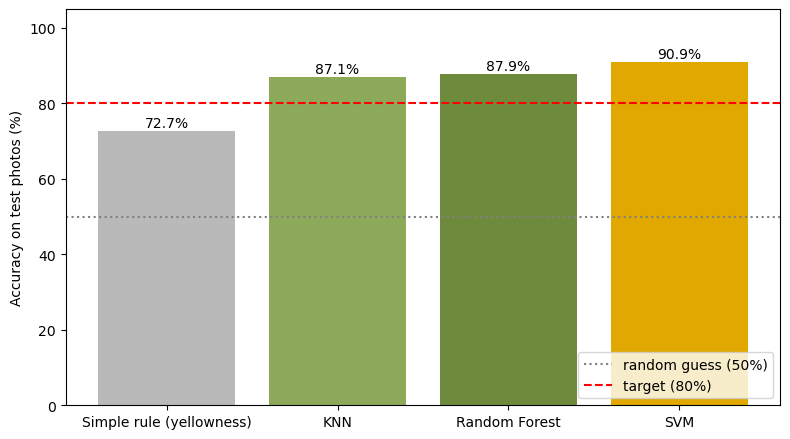

In [19]:
# bar chart of the test accuracy
colors = ["#B9B9B9", "#8DAA5B", "#6E8B3D", "#E0A800"]
plt.figure(figsize=(8, 4.5))
bars = plt.bar(results["Model"], results["Test accuracy %"], color=colors)
plt.axhline(50, color="grey", linestyle=":", label="random guess (50%)")
plt.axhline(80, color="red", linestyle="dashed", label="target (80%)")
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{b.get_height():.1f}%", ha="center")
plt.ylim(0, 105)
plt.ylabel("Accuracy on test photos (%)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig08_model_accuracy.png"), dpi=150, bbox_inches="tight")
plt.show()

Best model: SVM
              precision    recall  f1-score   support

     carbide      0.922     0.894     0.908        66
     natural      0.897     0.924     0.910        66

    accuracy                          0.909       132
   macro avg      0.909     0.909     0.909       132
weighted avg      0.909     0.909     0.909       132



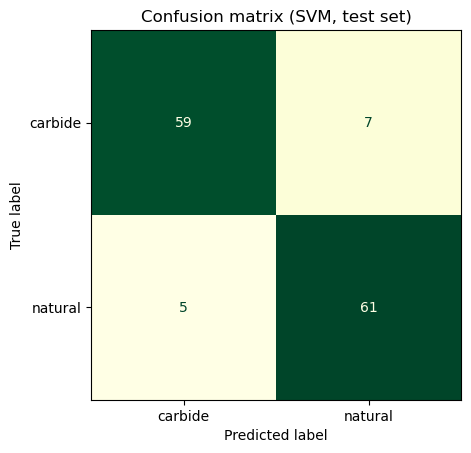

In [20]:
# look closer at the best model
best_name = results.iloc[1:].sort_values("Test accuracy %", ascending=False).iloc[0]["Model"]
best_model = models[best_name]
test_pred = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(y_test, test_pred, digits=3))

cm = confusion_matrix(y_test, test_pred, labels=["carbide", "natural"])
ConfusionMatrixDisplay(cm, display_labels=["carbide", "natural"]).plot(cmap="YlGn", colorbar=False)
plt.title(f"Confusion matrix ({best_name}, test set)")
plt.savefig(os.path.join(FIGURE_FOLDER, "fig09_confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

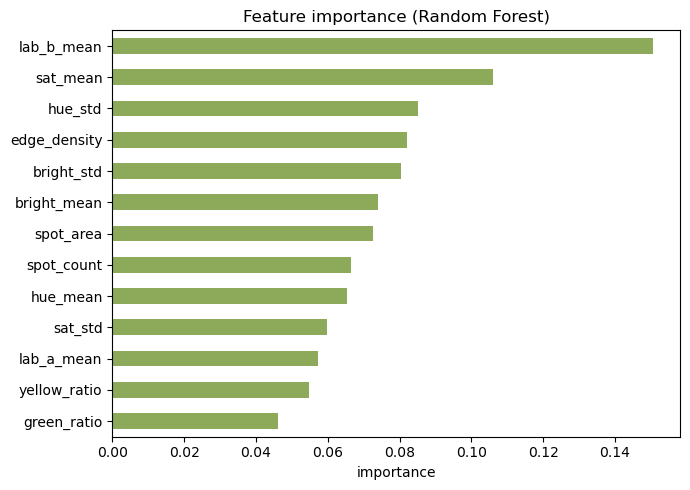

In [21]:
# which features help the most? (random forest can tell us)
forest = models["Random Forest"]
importance = pd.Series(forest.feature_importances_, index=feature_names).sort_values()

plt.figure(figsize=(7, 5))
importance.plot(kind="barh", color="#8DAA5B")
plt.title("Feature importance (Random Forest)")
plt.xlabel("importance")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig10_feature_importance.png"), dpi=150, bbox_inches="tight")
plt.show()

## 12. Evaluation
### 12.1 Does enhancement actually help?
On the clean dataset photos the accuracy is about the same with or without enhancement, because the photos are already good.
The real value shows up on **bad photos**. We add noise to 60 photos and compare the banana mask with the mask from the clean photo using **IoU** (Intersection over Union, 1.0 = perfect match).

In [22]:
def iou(mask_a, mask_b):
    '''
    summary: how much two masks overlap, 1 = exactly the same, 0 = no overlap
    '''
    a, b = mask_a > 0, mask_b > 0
    return (a & b).sum() / max((a | b).sum(), 1)


test_photos = random.sample(paths, 60)
noise_rows = []
for strength in [15, 30]:
    iou_without, iou_with, spots_clean, spots_without, spots_with = [], [], [], [], []
    for p in test_photos:
        clean = load_image(p)
        clean_enh = enhance_image(clean)
        reference_mask, _, _ = segment_banana(clean_enh)
        noisy = add_noise(clean, strength)

        # pipeline without the enhancement step
        mask_without, _, _ = segment_banana(noisy)
        # pipeline with the enhancement step
        noisy_enh = enhance_image(noisy)
        mask_with, _, _ = segment_banana(noisy_enh)

        iou_without.append(iou(mask_without, reference_mask))
        iou_with.append(iou(mask_with, reference_mask))
        spots_clean.append(len(count_spots(clean_enh, reference_mask)[0]))
        spots_without.append(len(count_spots(noisy, mask_without)[0]))
        spots_with.append(len(count_spots(noisy_enh, mask_with)[0]))

    noise_rows.append({"Noise strength": strength,
                       "Mask IoU without enhancement": round(np.mean(iou_without), 2),
                       "Mask IoU with enhancement": round(np.mean(iou_with), 2),
                       "Spots on clean photo": round(np.mean(spots_clean)),
                       "Spots without enhancement": round(np.mean(spots_without)),
                       "Spots with enhancement": round(np.mean(spots_with))})

noise_table = pd.DataFrame(noise_rows)
noise_table

,Noise strength,Mask IoU without enhancement,Mask IoU with enhancement,Spots on clean photo,Spots without enhancement,Spots with enhancement
0,15,0.45,0.98,59,192,80
1,30,0.00,0.86,59,0,134


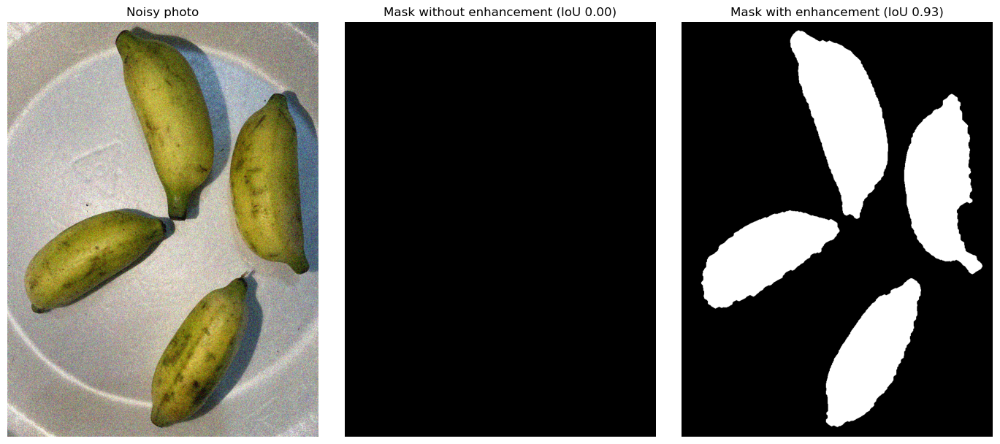

In [23]:
# show what happens to the mask on one noisy photo
noisy = add_noise(carbide_img, 30)
mask_without, _, _ = segment_banana(noisy)
mask_with, _, _ = segment_banana(enhance_image(noisy))

fig, ax = plt.subplots(1, 3, figsize=(14, 6))
ax[0].imshow(noisy)
ax[0].set_title("Noisy photo")
ax[1].imshow(mask_without, cmap="gray")
ax[1].set_title(f"Mask without enhancement (IoU {iou(mask_without, carbide_mask):.2f})")
ax[2].imshow(mask_with, cmap="gray")
ax[2].set_title(f"Mask with enhancement (IoU {iou(mask_with, carbide_mask):.2f})")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig11_noise_test.png"), dpi=150, bbox_inches="tight")
plt.show()

### 12.2 Some test predictions
Green title = correct, red title = wrong.

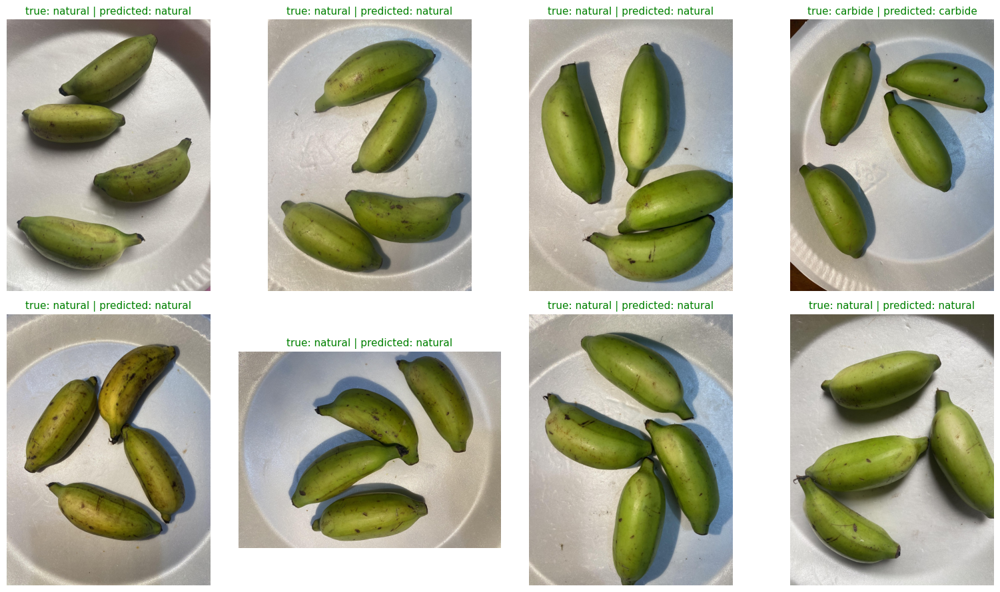

In [24]:
# show 8 random test photos with the prediction of the best model
show_idx = random.sample(range(len(path_test)), 8)
fig, ax = plt.subplots(2, 4, figsize=(16, 9))
for a, i in zip(ax.flat, show_idx):
    true_label = y_test.iloc[i]
    pred_label = test_pred[i]
    a.imshow(load_image(path_test.iloc[i]))
    a.set_title(f"true: {true_label} | predicted: {pred_label}",
                color="green" if true_label == pred_label else "red", fontsize=11)
    a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig12_predictions.png"), dpi=150, bbox_inches="tight")
plt.show()

In [25]:
# save the main numbers so the README can quote them
summary = results.copy()
summary.to_csv(os.path.join(RESULTS_FOLDER, "model_results.csv"), index=False)
noise_table.to_csv(os.path.join(RESULTS_FOLDER, "noise_test.csv"), index=False)
print(summary)
print(noise_table)

                      Model  Test accuracy %  5 fold CV accuracy %
0  Simple rule (yellowness)             72.7                   NaN
1                       KNN             87.1                  83.4
2             Random Forest             87.9                  86.0
3                       SVM             90.9                  88.7
   Noise strength  Mask IoU without enhancement  Mask IoU with enhancement  \
0              15                          0.45                       0.98   
1              30                          0.00                       0.86   

   Spots on clean photo  Spots without enhancement  Spots with enhancement  
0                    59                        192                      80  
1                    59                          0                     134  


## 13. Conclusion
**What worked**
* Segmentation with Otsu on the saturation channel separates the bananas from the plate very well.
* The best model (SVM) reached **90.9% accuracy** on photos it never saw (5 fold cross validation: **88.7%**), above the 80% target I set at the start. A single color rule only got **72.7%**, so combining color, spots and texture really helps.
* For comparison, the dataset paper reports 80% with DenseNet201 and 72% with ResNet50 (deep learning). Their test setup is different, so it is not a direct comparison, but this much simpler pipeline lands in the same range.
* The enhancement step is what keeps the pipeline working on noisy photos (mask IoU stays high while the version without enhancement fails).

**Limitations**
* The photos come from a small number of bananas, one banana type (Sabri), one place (Bangladesh) and one camera. It probably won't transfer to bananas from a Canadian grocery store without new data.
* The model may also learn small differences in light or time of day between the two photo sessions, not only the carbide effect.
* The amount of carbide used was not recorded.
* A photo can only show the outside of the banana. It cannot measure chemicals.

**Next steps:** more bananas from different farms and markets, photos taken in real market lighting, watershed segmentation to split touching bananas, and a CNN baseline on the same cleaned split.

**Verdict:** good enough as a **quick screening tool** (for example a phone app that tells an inspector which batch to send to the lab), but **not** as proof. The final decision needs a lab test.